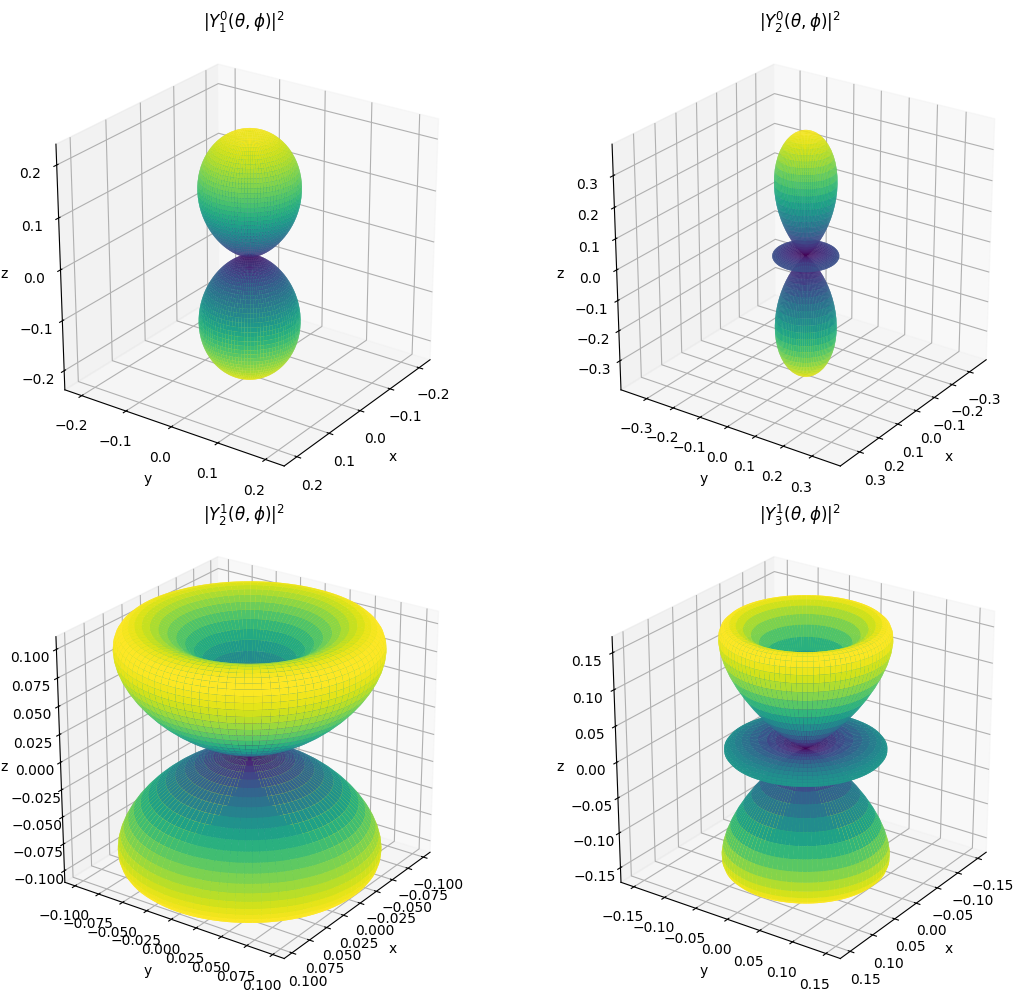

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors

def assoc_legendre(l, m, x):
    p_mm = np.ones_like(x, dtype=float)
    if m > 0:
        somx2 = np.sqrt(np.clip(1.0 - x**2, 0.0, None))
        fact = 1.0
        for _ in range(1, m + 1):
            p_mm *= -fact * somx2
            fact += 2.0

    if l == m:
        return p_mm

    p_mmp1 = x * (2 * m + 1) * p_mm
    if l == m + 1:
        return p_mmp1

    p_ll = np.zeros_like(x, dtype=float)
    for ll in range(m + 2, l + 1):
        p_ll = ((2 * ll - 1) * x * p_mmp1 - (ll + m - 1) * p_mm) / (ll - m)
        p_mm, p_mmp1 = p_mmp1, p_ll

    return p_ll

def spherical_harmonic(l, m, theta, phi):
    m_abs = abs(m)
    norm = np.sqrt(((2 * l + 1) / (4 * np.pi)) * (math.factorial(l - m_abs) / math.factorial(l + m_abs)))
    
    P_lm = assoc_legendre(l, m_abs, np.cos(theta))
    Y_lm = norm * P_lm * np.exp(1j * m_abs * phi)

    if m < 0:
        Y_lm = ((-1) ** m_abs) * np.conjugate(Y_lm)
    return Y_lm

def plot_spherical_harmonics(states, n_points=100):
    theta = np.linspace(0, np.pi, n_points)
    phi = np.linspace(0, 2 * np.pi, n_points)
    THETA, PHI = np.meshgrid(theta, phi)

    fig = plt.figure(figsize=(12, 10))

    for idx, (l, m) in enumerate(states, 1):
        Y = spherical_harmonic(l, m, THETA, PHI)
        prob_density = np.abs(Y) ** 2

        X = prob_density * np.sin(THETA) * np.cos(PHI)
        Y_coord = prob_density * np.sin(THETA) * np.sin(PHI)
        Z = prob_density * np.cos(THETA)

        ax = fig.add_subplot(2, 2, idx, projection='3d')
        
        norm = colors.Normalize(vmin=prob_density.min(), vmax=prob_density.max())
        face_colors = cm.viridis(norm(prob_density))

        ax.plot_surface(X, Y_coord, Z, facecolors=face_colors, rstride=1, cstride=1,
                        linewidth=0, antialiased=True, shade=False)

        max_range = max(np.max(np.abs(X)), np.max(np.abs(Y_coord)), np.max(np.abs(Z)))
        if max_range == 0:
            max_range = 1.0
        ax.set_xlim(-max_range, max_range)
        ax.set_ylim(-max_range, max_range)
        ax.set_zlim(-max_range, max_range)
        ax.set_box_aspect((1, 1, 1))

        ax.set_title(rf"$|Y_{{{l}}}^{{{m}}}(\theta, \phi)|^2$")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_zlabel("z")
        ax.view_init(elev=25, azim=35)

    plt.tight_layout()
    plt.show()

states_to_plot = [(1, 0), (2, 0), (2, 1), (3, 1)]
plot_spherical_harmonics(states_to_plot)